
## EDA and feature engineering


In [2]:
from pathlib import Path
import json, sys, shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from scipy.sparse import issparse
from IPython.display import display

INPUT = Path("weaving_rejection_eda_input.csv")
OUT = Path("member02_combined_outputs")
GRAPHS = OUT / "graphs"
GRAPHS.mkdir(parents=True, exist_ok=True)
TARGET = "Rejection"
GROUP = "Order_Group"
SEED = 42

df = pd.read_csv(INPUT, dtype={"ID": str})
print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (22010, 16)


,ID,Month,Construction,Req_Finish_Fabrics,Fabric_Allowance,Rec_Beam_length(yds),Shrink_allow,Previous_pdn,Req_grey_fabric,Req_beam_length(yds),Total_Pdn(yds),Rejection,warp_count,weft_count,epi,ppi
0,12207-8,January,40+40/2/40/110x80,31300.0,6.0,38286.9360,12.5,26717,33297.872340,34797.651103,27646.0,285,40,80.0,110,80
1,12228-1,January,40x40/110x90,10450.0,7.0,13057.5840,14.5,11019,11236.559140,12017.350432,11019.0,39,40,40.0,110,90
2,12249-6(B),January,40x40/110x80,900.0,11.5,1902.8640,12.5,1528,1016.949153,1062.753843,1528.0,0,40,40.0,110,80
3,12277-5,January,40x40/130x80,8000.0,8.0,10093.9280,14.0,8944,8695.652174,9245.815159,8944.0,58,40,40.0,130,80
4,12284-1(A),January,50x50/140x70,3500.0,8.1,69146.1408,9.1,58680,3808.487486,3831.158751,59367.0,1043,50,50.0,140,70


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22010 entries, 0 to 22009
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID                    22010 non-null  object 
 1   Month                 22010 non-null  object 
 2   Construction          22010 non-null  object 
 3   Req_Finish_Fabrics    22010 non-null  float64
 4   Fabric_Allowance      22010 non-null  float64
 5   Rec_Beam_length(yds)  22010 non-null  float64
 6   Shrink_allow          22010 non-null  float64
 7   Previous_pdn          22010 non-null  int64  
 8   Req_grey_fabric       22010 non-null  float64
 9   Req_beam_length(yds)  22010 non-null  float64
 10  Total_Pdn(yds)        22010 non-null  float64
 11  Rejection             22010 non-null  int64  
 12  warp_count            22010 non-null  int64  
 13  weft_count            22010 non-null  float64
 14  epi                   22010 non-null  int64  
 15  ppi                

In [3]:
required = ["ID", "Month", "Construction", "Req_Finish_Fabrics",
            "Fabric_Allowance", "Rec_Beam_length(yds)", "Shrink_allow",
            "Previous_pdn", "Req_grey_fabric", "Req_beam_length(yds)",
            "Total_Pdn(yds)", TARGET, "warp_count", "weft_count", "epi", "ppi"]
assert not (set(required) - set(df.columns)), "Missing required columns"
assert df["ID"].notna().all()
assert df[TARGET].notna().all() and np.isfinite(df[TARGET]).all()
assert (df[TARGET] >= 0).all()

missing = df.isna().sum().rename("missing").to_frame()
display(missing)
missing.to_csv(OUT / "missing_values.csv")

audit = {
    "rows": len(df), "columns": len(df.columns),
    "unique_raw_ids": df["ID"].nunique(),
    "exact_duplicate_rows_beyond_first": int(df.duplicated().sum()),
    "missing_cells": int(df.isna().sum().sum()),
    "zero_target": int((df[TARGET] == 0).sum()),
    "positive_target": int((df[TARGET] > 0).sum()),
    "positive_ids": int(df.loc[df[TARGET] > 0, "ID"].nunique())
}
print(audit)
df[GROUP] = df["ID"].str.strip()
assert df[GROUP].ne("").all()

id_audit = df.groupby(GROUP).agg(
    records=("ID", "size"),
    months=("Month", "nunique"),
    constructions=("Construction", "nunique")
).reset_index()
id_audit["no_digits"] = ~id_audit[GROUP].str.contains(r"\d")
id_audit["combined_or_parenthesized"] = id_audit[GROUP].str.contains(r"[+()]")
display(id_audit[id_audit.no_digits | (id_audit.constructions > 1)])
id_audit.to_csv(OUT / "order_id_audit.csv", index=False)
(OUT / "data_audit.json").write_text(json.dumps(audit, indent=2))

,missing
ID,0
Month,0
Construction,0
Req_Finish_Fabrics,0
Fabric_Allowance,0
Rec_Beam_length(yds),0
Shrink_allow,0
Previous_pdn,0
Req_grey_fabric,0
Req_beam_length(yds),0


{'rows': 22010, 'columns': 16, 'unique_raw_ids': 978, 'exact_duplicate_rows_beyond_first': 10940, 'missing_cells': 0, 'zero_target': 6746, 'positive_target': 15264, 'positive_ids': 684}


,Order_Group,records,months,constructions,no_digits,combined_or_parenthesized
200,13072-9,21,3,2,False,False
201,13072-9(A),41,2,2,False,True
263,13086-9,38,2,2,False,False
323,13103-2,25,1,2,False,False
605,13223-5,26,1,2,False,False
647,13240-2,25,1,2,False,False
752,Beam,2,1,1,True,False
753,ED-13001,31,2,2,False,False
754,Exc-Beam,8,1,1,True,False
755,Exces Beam,10,1,1,True,False


203

In [5]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
dev_idx, test_idx = next(splitter.split(df, groups=df[GROUP]))
dev = df.iloc[dev_idx].copy()
test = df.iloc[test_idx].copy()
assert set(dev[GROUP]).isdisjoint(test[GROUP])
print("Development:", len(dev), "rows;", dev[GROUP].nunique(), "groups")
print("Test:", len(test), "rows;", test[GROUP].nunique(), "groups")
split = pd.concat([
    pd.DataFrame({GROUP: dev[GROUP].unique(), "Split": "Development"}),
    pd.DataFrame({GROUP: test[GROUP].unique(), "Split": "Test"})
], ignore_index=True)
assert split[GROUP].is_unique
split.to_csv(OUT / "order_split.csv", index=False)

Development: 17452 rows; 782 groups
Test: 4558 rows; 196 groups


In [6]:
BASE_NUM = ["Req_Finish_Fabrics", "Fabric_Allowance", "Shrink_allow",
            "Req_grey_fabric", "Req_beam_length(yds)", "warp_count",
            "weft_count", "epi", "ppi"]
CAT = ["Construction"]
EXCLUDED = ["ID", GROUP, "Month", "Previous_pdn", "Total_Pdn(yds)",
            "Rec_Beam_length(yds)", TARGET]
display(dev[BASE_NUM + [TARGET]].describe().T)
dev[BASE_NUM + [TARGET]].describe().T.to_csv(OUT / "numerical_summary.csv")
for c in ["Construction", "Month", "warp_count", "weft_count"]:
    print(c, "unique:", dev[c].nunique())
    display(dev[c].value_counts().head(10))

,count,mean,std,min,25%,50%,75%,max
Req_Finish_Fabrics,17452.0,9614.460864,21380.069340,50.000000,1300.000000,2900.000000,6699.000000,172800.000000
Fabric_Allowance,17452.0,9.151536,3.688769,5.000000,7.000000,8.000000,10.000000,37.200000
Shrink_allow,17452.0,13.391396,3.032090,6.000000,11.300000,14.000000,14.600000,40.800000
Req_grey_fabric,17452.0,10384.766888,23063.454917,54.347826,1500.000000,3162.486369,7203.225806,192427.616927
Req_beam_length(yds),17452.0,10852.842544,24097.835932,56.473019,1572.400073,3280.672144,7463.520970,211997.533212
warp_count,17452.0,41.537360,7.590505,20.000000,40.000000,40.000000,40.000000,120.000000
weft_count,17452.0,41.341394,7.739446,20.000000,40.000000,40.000000,40.000000,140.000000
epi,17452.0,120.178948,15.325233,30.000000,110.000000,120.000000,130.000000,170.000000
ppi,17452.0,82.014497,9.512383,42.000000,80.000000,80.000000,90.000000,110.000000
Rejection,17452.0,58.473699,180.390241,0.000000,0.000000,12.000000,44.000000,3262.000000


Construction unique: 112


,count
Construction,
40x40/110x90,2851
40x40/120x80,2726
40x40/130x80,2069
40x40/110x70,1064
40x40/120x90,979
40x40/100x70,885
40x40/130x90,852
50x50/140x80,562
20x20/82x64,343


Month unique: 9


,count
Month,
September,2485
June,2382
April,2227
May,2124
July,1994
March,1774
January,1735
August,1509
February,1222


warp_count unique: 8


,count
warp_count,
40,13566
50,2286
30,634
60,376
20,359
80,204
120,20
70,7


weft_count unique: 10


,count
weft_count,
40.0,13581
50.0,2292
30.0,668
20.0,395
60.0,390
100.0,45
80.0,44
120.0,20
140.0,10


## Development-set EDA

Zero: 5389 Positive: 12063
Positive groups: 546


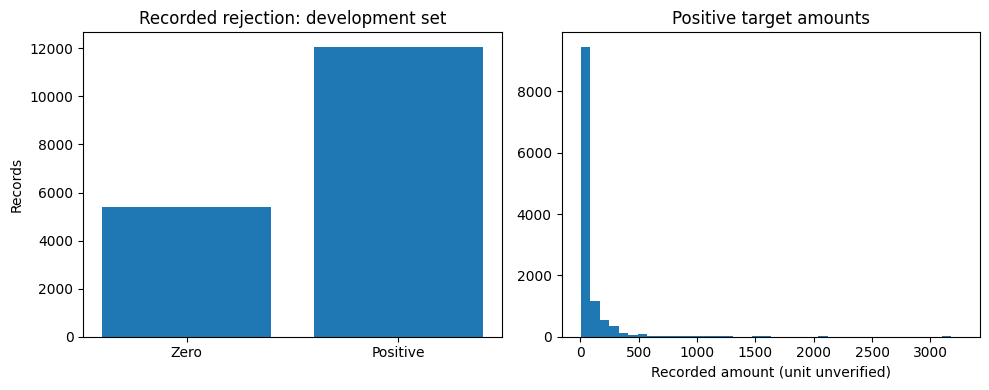

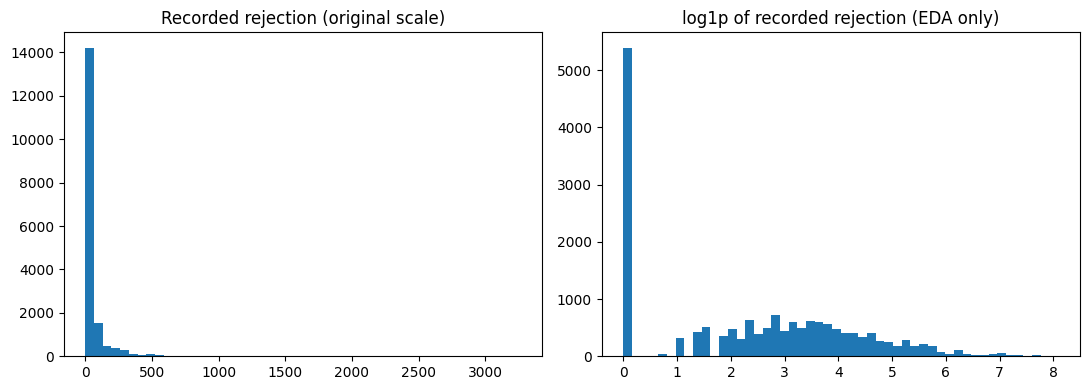

,Rejection
count,17452.000000
mean,58.473699
std,180.390241
min,0.000000
25%,0.000000
50%,12.000000
75%,44.000000
max,3262.000000


In [7]:
def save_plot(name):
    plt.tight_layout()
    plt.savefig(GRAPHS / name, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

zero = int(dev[TARGET].eq(0).sum())
positive = int(dev[TARGET].gt(0).sum())
print("Zero:", zero, "Positive:", positive)
print("Positive groups:", dev.loc[dev[TARGET].gt(0), GROUP].nunique())
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].bar(["Zero", "Positive"], [zero, positive])
ax[0].set_title("Recorded rejection: development set")
ax[0].set_ylabel("Records")
ax[1].hist(dev.loc[dev[TARGET].gt(0), TARGET], bins=40)
ax[1].set_title("Positive target amounts")
ax[1].set_xlabel("Recorded amount (unit unverified)")
save_plot("target_distribution.png")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(dev[TARGET], bins=50)
ax[0].set_title("Recorded rejection (original scale)")
ax[1].hist(np.log1p(dev[TARGET]), bins=50)
ax[1].set_title("log1p of recorded rejection (EDA only)")
save_plot("target_skewness.png")
display(dev[TARGET].describe())


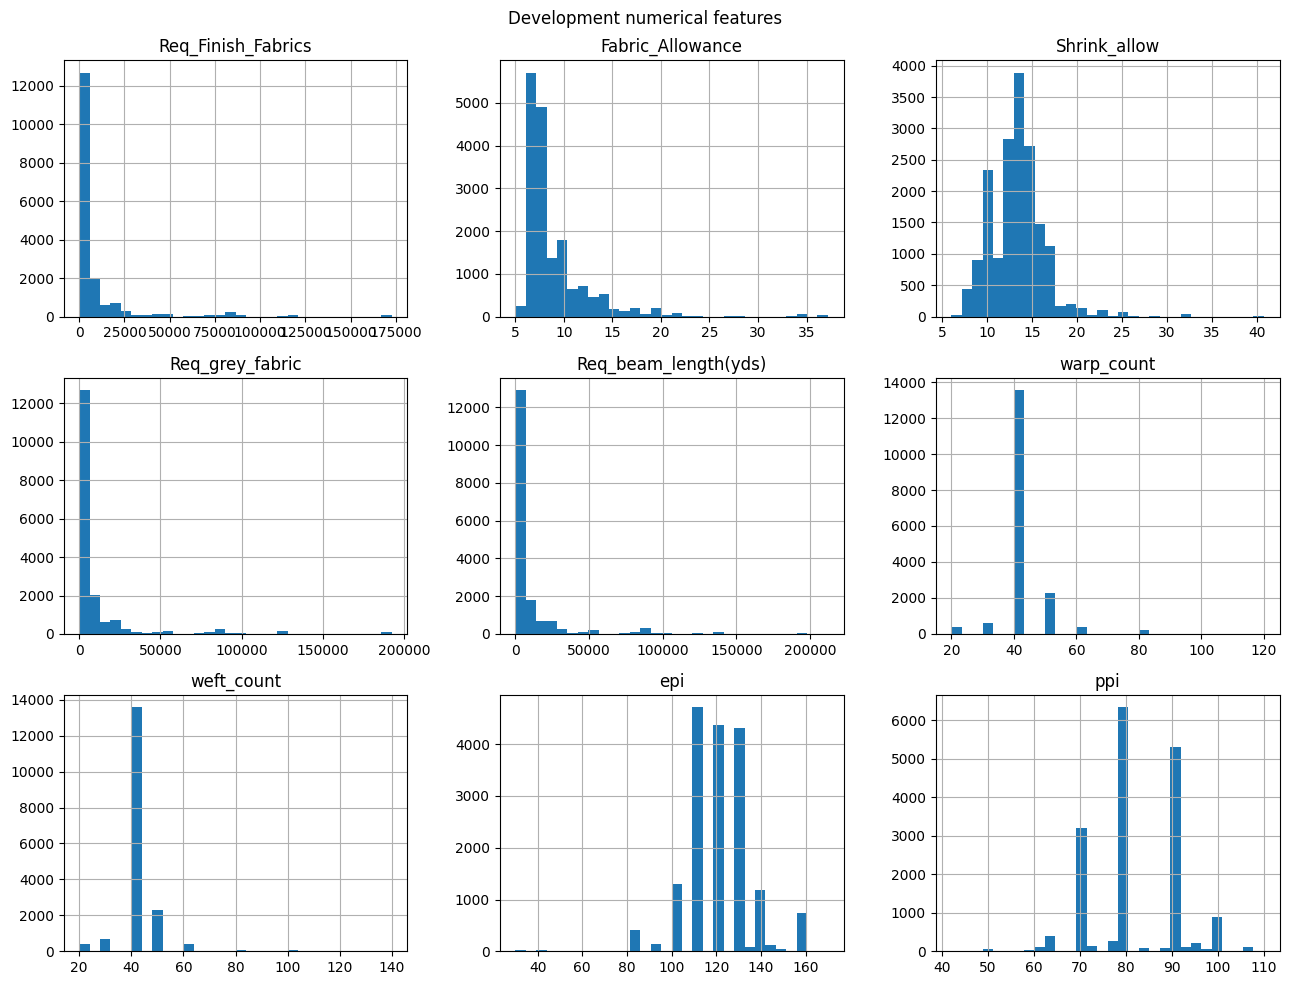

In [8]:
dev[BASE_NUM].hist(bins=30, figsize=(13, 10))
plt.suptitle("Development numerical features")
save_plot("histograms.png")

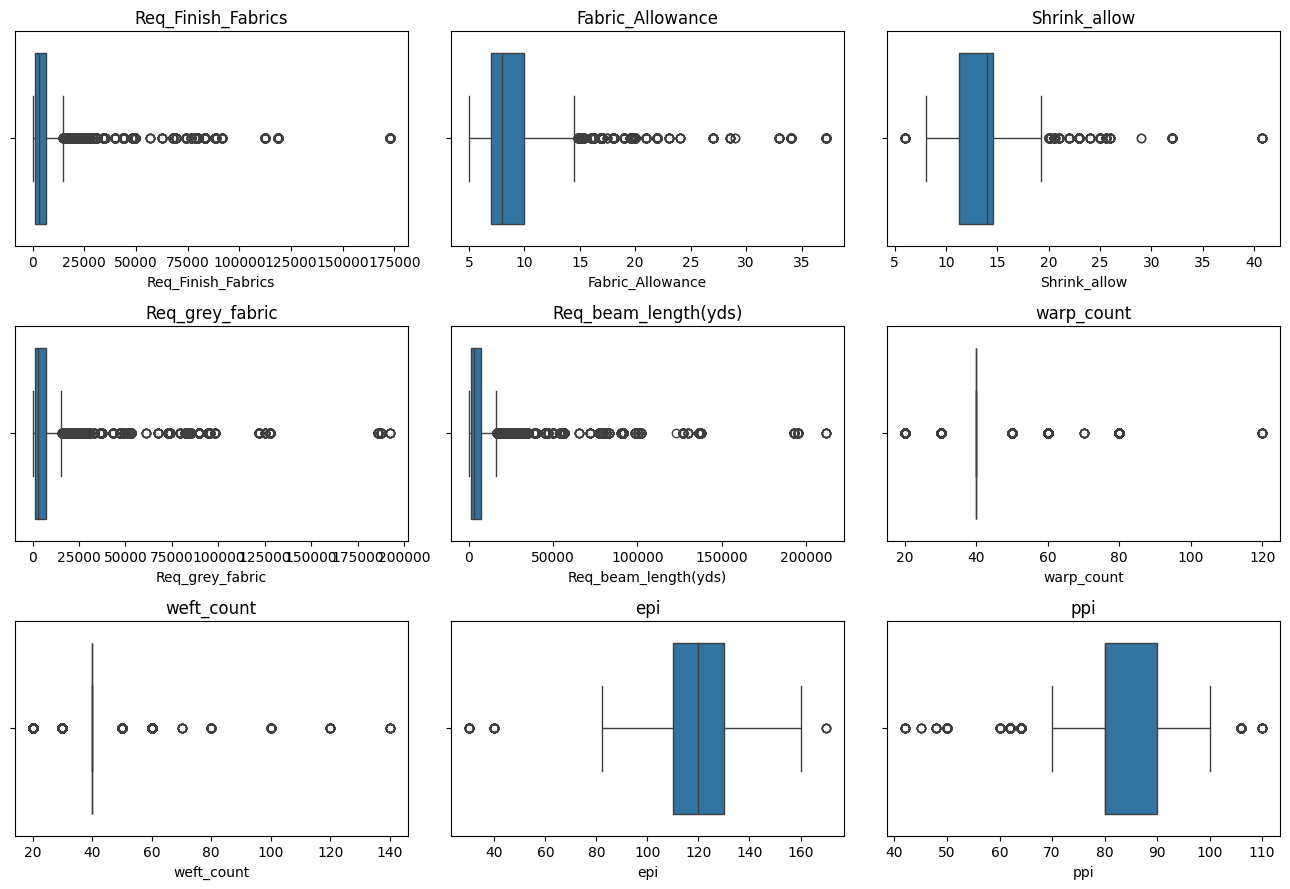

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for c, ax in zip(BASE_NUM, axes.flat):
    sns.boxplot(x=dev[c], ax=ax)
    ax.set_title(c)
save_plot("boxplots.png")

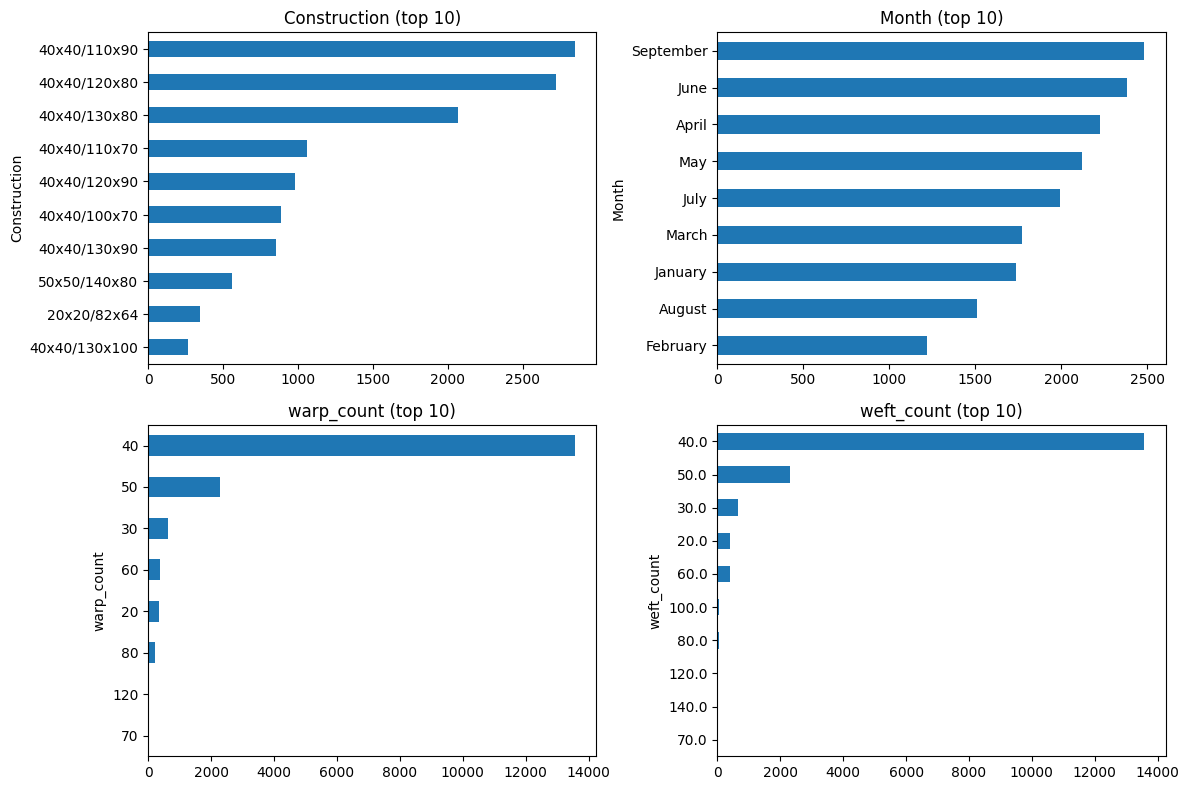

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for c, ax in zip(["Construction", "Month", "warp_count", "weft_count"], axes.flat):
    dev[c].value_counts().head(10).sort_values().plot.barh(ax=ax)
    ax.set_title(c + " (top 10)")
save_plot("categorical_analysis.png")

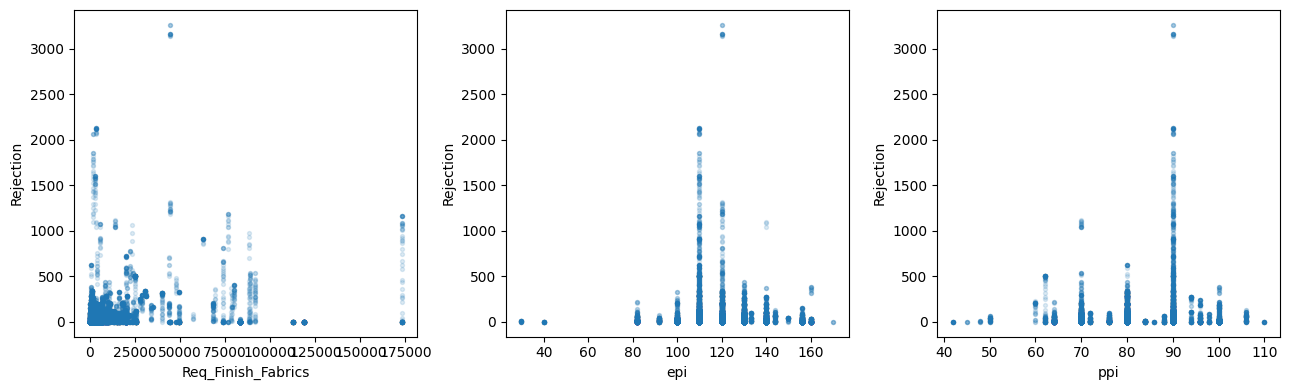

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for c, ax in zip(["Req_Finish_Fabrics", "epi", "ppi"], axes):
    ax.scatter(dev[c], dev[TARGET], alpha=0.15, s=8)
    ax.set_xlabel(c)
    ax.set_ylabel(TARGET)
save_plot("scatter_plots.png")

In [13]:
module_code = 'import numpy as np\nimport pandas as pd\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import OneHotEncoder, StandardScaler\nfrom sklearn.pipeline import Pipeline\n\nBASE_NUM = ["Req_Finish_Fabrics", "Fabric_Allowance", "Shrink_allow",\n            "Req_grey_fabric", "Req_beam_length(yds)", "warp_count",\n            "weft_count", "epi", "ppi"]\nCAT = ["Construction"]\nENGINEERED = ["Thread_Density", "EPI_PPI_Ratio", "Log_Order_Size",\n              "Fabric_Expansion_Ratio"]\n\ndef engineer_features(data):\n    data = data.copy()\n    for c in BASE_NUM:\n        data[c] = pd.to_numeric(data[c], errors="coerce")\n    data[BASE_NUM] = data[BASE_NUM].replace([np.inf, -np.inf], np.nan)\n    data["Thread_Density"] = data["epi"] + data["ppi"]\n    data["EPI_PPI_Ratio"] = data["epi"] / data["ppi"].where(data["ppi"] > 0)\n    data["Log_Order_Size"] = np.log1p(data["Req_Finish_Fabrics"].where(data["Req_Finish_Fabrics"] >= 0))\n    data["Fabric_Expansion_Ratio"] = data["Req_grey_fabric"] / data["Req_Finish_Fabrics"].where(data["Req_Finish_Fabrics"] > 0)\n    data[ENGINEERED] = data[ENGINEERED].replace([np.inf, -np.inf], np.nan)\n    for c in CAT:\n        data[c] = data[c].map(lambda x: str(x).strip() if pd.notna(x) else np.nan)\n        data[c] = data[c].replace("", np.nan)\n    return data\n\ndef feature_lists(variant="engineered"):\n    if variant == "original":\n        return BASE_NUM.copy(), CAT.copy()\n    if variant == "engineered":\n        return BASE_NUM + ENGINEERED, CAT.copy()\n    if variant == "reduced":\n        return [c for c in BASE_NUM if c not in ["Req_grey_fabric", "Req_beam_length(yds)"]] + ENGINEERED, CAT.copy()\n    if variant == "compact":\n        return ["Log_Order_Size", "Fabric_Allowance", "Shrink_allow",\n                "warp_count", "weft_count", "epi", "ppi",\n                "Thread_Density", "EPI_PPI_Ratio"], CAT.copy()\n    raise ValueError("Unknown feature variant")\n\ndef build_preprocessor(scale_numeric=False, variant="engineered"):\n    numeric, categorical = feature_lists(variant)\n    steps = [("imputer", SimpleImputer(strategy="median"))]\n    if scale_numeric:\n        steps.append(("scaler", StandardScaler()))\n    return ColumnTransformer([\n        ("num", Pipeline(steps), numeric),\n        ("cat", Pipeline([\n            ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),\n            ("encoder", OneHotEncoder(handle_unknown="ignore"))\n        ]), categorical)\n    ])\n'
(OUT / "preprocessing.py").write_text(module_code, encoding="utf-8")
# Execute exactly the reusable source saved for Member 03.
exec(compile(module_code, str(OUT / "preprocessing.py"), "exec"))
dev_eng = engineer_features(dev)
numeric_features, categorical_features = feature_lists("engineered")
selected_features = numeric_features + categorical_features
VARIANTS = ["original", "engineered", "reduced", "compact"]
feature_table = pd.DataFrame([
    {"Feature": c, **{v: c in sum(feature_lists(v), []) for v in VARIANTS}}
    for c in selected_features
])
feature_table.to_csv(OUT / "candidate_feature_list.csv", index=False)
display(feature_table)
display(dev_eng[ENGINEERED].head())


,Feature,original,engineered,reduced,compact
0,Req_Finish_Fabrics,True,True,True,False
1,Fabric_Allowance,True,True,True,True
2,Shrink_allow,True,True,True,True
3,Req_grey_fabric,True,True,False,False
4,Req_beam_length(yds),True,True,False,False
5,warp_count,True,True,True,True
6,weft_count,True,True,True,True
7,epi,True,True,True,True
8,ppi,True,True,True,True
9,Thread_Density,False,True,True,True


,Thread_Density,EPI_PPI_Ratio,Log_Order_Size,Fabric_Expansion_Ratio
0,190,1.375000,10.351405,1.063830
1,200,1.222222,9.254453,1.075269
2,190,1.375000,6.803505,1.129944
3,210,1.625000,8.987322,1.086957
4,210,2.000000,8.160804,1.088139


In [14]:
cv = GroupKFold(n_splits=5)
groups = dev_eng[GROUP]
y = dev_eng[TARGET]
X = dev_eng[selected_features]

for name, scaling in [("Ridge", True), ("Tree", False)]:
    for fold, (a, b) in enumerate(cv.split(X, y, groups), 1):
        assert set(groups.iloc[a]).isdisjoint(groups.iloc[b])
        pre = build_preprocessor(scale_numeric=scaling)
        tr = pre.fit_transform(X.iloc[a])
        va = pre.transform(X.iloc[b])
        for mat in (tr, va):
            values = mat.data if issparse(mat) else mat
            assert np.isfinite(values).all()
        print(name, "fold", fold, "passed:", tr.shape, va.shape)

Ridge fold 1 passed: (13961, 115) (3491, 115)
Ridge fold 2 passed: (13961, 115) (3491, 115)
Ridge fold 3 passed: (13962, 116) (3490, 116)
Ridge fold 4 passed: (13962, 113) (3490, 113)
Ridge fold 5 passed: (13962, 109) (3490, 109)
Tree fold 1 passed: (13961, 115) (3491, 115)
Tree fold 2 passed: (13961, 115) (3491, 115)
Tree fold 3 passed: (13962, 116) (3490, 116)
Tree fold 4 passed: (13962, 113) (3490, 113)
Tree fold 5 passed: (13962, 109) (3490, 109)


In [15]:
results = []
baseline_scores = -cross_val_score(
    DummyRegressor(strategy="median"), X, y, groups=groups,
    cv=cv, scoring="neg_mean_absolute_error", error_score="raise"
)
results.append({"feature_set": "median_baseline", "features": 0,
                "mean_cv_mae": baseline_scores.mean(), "std_cv_mae": baseline_scores.std()})
for variant in VARIANTS:
    num, cat = feature_lists(variant)
    pipe = Pipeline([
        ("preprocessing", build_preprocessor(True, variant)),
        ("ridge", Ridge(alpha=1.0, solver="lsqr"))
    ])
    scores = -cross_val_score(pipe, dev_eng[num + cat], y, groups=groups,
                              cv=cv, scoring="neg_mean_absolute_error",
                              error_score="raise")
    results.append({"feature_set": variant, "features": len(num + cat),
                    "mean_cv_mae": scores.mean(), "std_cv_mae": scores.std()})
feature_comparison = pd.DataFrame(results)
display(feature_comparison)
feature_comparison.to_csv(OUT / "provisional_feature_comparison.csv", index=False)


,feature_set,features,mean_cv_mae,std_cv_mae
0,median_baseline,0,56.146720,11.487434
1,original,10,72.444979,9.849776
2,engineered,14,72.416999,9.744826
3,reduced,12,72.800515,9.104079
4,compact,10,72.833324,9.345872


In [16]:
all_eng = engineer_features(df)
export_cols = ["ID", GROUP] + selected_features + [TARGET]
export = all_eng[export_cols]
export.to_csv(OUT / "df_member02.csv", index=False)
config = {
    "status": "provisional_not_final_training_approved",
    "source": INPUT.name, "target": TARGET, "group_column": GROUP,
    "raw_id_column": "ID", "random_state": SEED,
    "numeric_features": numeric_features, "categorical_features": categorical_features,
    "engineered_features": ENGINEERED,
    "feature_variants": {v: sum(feature_lists(v), []) for v in VARIANTS},
    "excluded": EXCLUDED, "sklearn_version": sklearn.__version__,
    "pandas_version": pd.__version__,
    "notes": ["Verify target unit, observation level, IDs, duplicate semantics and prediction-time inputs before final training."]
}
(OUT / "feature_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
summary = f'''# Member 02 handover (provisional)
Input: {INPUT.name}
Rows: {len(df)}; original columns: {audit["columns"]}; positive targets: {audit["positive_target"]}; zero targets: {audit["zero_target"]}.
Development: {len(dev)} rows, {dev[GROUP].nunique()} exact groups.
Test: {len(test)} rows, {test[GROUP].nunique()} exact groups.
Candidate features: {len(selected_features)}, including {len(ENGINEERED)} engineered features.
Duplicate rows beyond first: {audit["exact_duplicate_rows_beyond_first"]}; retained pending verification.
Three production variables and Month excluded due to unverified prediction-time availability.
Target semantics, order alias mapping and duplicate handling remain unresolved.
Use order_split.csv and fit preprocessing only inside grouped training folds. Do not use test outcomes for model selection.
The feature comparison is development-only screening, not final model evaluation.\nGrouped CV screening MAE (lower is better): {feature_comparison.set_index("feature_set")["mean_cv_mae"].round(3).to_dict()}
'''
(OUT / "feature_engineering_summary.md").write_text(summary, encoding="utf-8")
print("Exported shape:", export.shape)
print("Saved graphs:", len(list(GRAPHS.glob("*.png"))))
archive = shutil.make_archive("Member02_Combined_Output", "zip", OUT)
print("Handover ZIP:", archive)

Exported shape: (22010, 17)
Saved graphs: 8
Handover ZIP: /content/Member02_Combined_Output.zip
